<a href="https://colab.research.google.com/github/Bernardo-techno/techno/blob/main/Copie_de_TP2_Attaque_FGSM_CNN_MNIST_Colab_FR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 2 - Attaque adversariale FGSM sur un CNN (MNIST)

Mastère 2 Expert IT Cyber - Technologies avancées - IA et cybersécurité

Durée indicative : 2 heures

Environnement : Google Colab et TensorFlow/Keras

## Objectifs pédagogiques

À la fin de ce TP, vous saurez :

1. Construire et entraîner un réseau de neurones convolutionnel (CNN) pour classer les chiffres manuscrits du jeu MNIST.
2. Expliquer le principe d'une attaque adversariale en boîte blanche.
3. Implémenter la méthode FGSM (Fast Gradient Sign Method) avec l'outil tf.GradientTape.
4. Mesurer la baisse de précision du modèle quand le paramètre epsilon augmente.
5. Visualiser les perturbations appliquées aux images.
6. Appliquer un entraînement adversarial et comparer la robustesse obtenue.

L'attaque est réalisée en laboratoire sur un modèle et un jeu de données publics. Elle ne vise aucun système tiers.

## Vocabulaire

* CNN. Ce réseau de neurones traite les images. Les convolutions détectent des motifs locaux, et le pooling réduit la taille des représentations.
* Gradient. Ce vecteur indique comment la fonction de perte évolue quand une entrée varie légèrement.
* FGSM. Cette méthode utilise le signe du gradient de la perte par rapport aux pixels pour construire une entrée perturbée.
* Epsilon. Ce paramètre limite l'amplitude de la perturbation appliquée à chaque pixel.
* Entraînement adversarial. Cette méthode entraîne le modèle avec un mélange d'images propres et d'images perturbées.

## À rendre

Vous devez rendre le notebook Colab exécuté avec le graphique de précision, trois visualisations d'images et une analyse écrite.

# Étape 0 - Ouvrir le notebook dans Google Colab

1. Dans Colab, cliquez sur Fichier puis Enregistrer une copie dans Drive.
2. Exécution, puis Modifier le type d'exécution, puis GPU si un GPU est proposé.
3. Exécutez les cellules l'une après l'autre avec le raccourci Shift + Entrée.

Le GPU accélère l'entraînement. Ce TP reste réalisable sur CPU. La plateforme Colab attribue les ressources de calcul selon la disponibilité.

Ce notebook est indépendant de l'exercice précédent sur le jeu NSL-KDD. Les variables et les modèles du TP1 ne sont pas réutilisés ici.

# Étape 1 - Initialiser l'environnement et charger MNIST

Nous utilisons directement TensorFlow et Keras. Nous allons coder l'attaque FGSM sans bibliothèque externe pour comprendre chaque étape du calcul.

In [1]:
# Importation des bibliothèques nécessaires pour le deep learning, le calcul et la visualisation
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Fixation des graines aléatoires pour garantir la reproductibilité des résultats
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Affichage des versions et de la disponibilité du GPU pour le diagnostic matériel
print("TensorFlow :", tf.__version__)
print("GPU disponible :", bool(tf.config.list_physical_devices("GPU")))

TensorFlow : 2.21.0
GPU disponible : True


## 1.1 - Charger les données

Le jeu MNIST contient 60000 images d'entraînement et 10000 images de test. Chaque image représente un chiffre manuscrit en niveaux de gris de 28 par 28 pixels. La classe associée est un chiffre de 0 à 9.

Keras télécharge automatiquement ce jeu de données lors de la première exécution.

In [2]:
# Chargement du jeu de données MNIST (images de chiffres manuscrits et leurs étiquettes)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Affichage des dimensions des ensembles d'entraînement et de test pour vérification
print("x_train :", x_train.shape) # Images d'entraînement (60 000 images de 28x28)
print("y_train :", y_train.shape) # Étiquettes d'entraînement correspondantes
print("x_test  :", x_test.shape)  # Images de test (10 000 images de 28x28)
print("y_test  :", y_test.shape)  # Étiquettes de test correspondantes

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
x_train : (60000, 28, 28)
y_train : (60000,)
x_test  : (10000, 28, 28)
y_test  : (10000,)


Les images d'origine contiennent des pixels codés par des entiers de 0 à 255. Le modèle et l'attaque ont besoin de valeurs normalisées entre 0 et 1.

In [3]:
# Conversion des étiquettes (labels) en entiers 32-bits
y_train = y_train.astype("int32")
y_test = y_test.astype("int32")

# Normalisation des pixels : conversion en float32 et division par 255.0 pour avoir des valeurs entre 0.0 et 1.0
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Ajout d'une dimension pour le canal de couleur (niveaux de gris, d'où 1 seul canal à la fin)
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

# Vérification des modifications et de l'intervalle de valeurs après normalisation
print("Nouvelle forme x_train :", x_train.shape)
print("Plage des pixels :", float(x_train.min()), "à", float(x_train.max()))

Nouvelle forme x_train : (60000, 28, 28, 1)
Plage des pixels : 0.0 à 1.0


## 1.2 - Afficher quelques images

Les étiquettes correspondent aux chiffres attendus. Le script suivant affiche un échantillon pour vérifier la cohérence des données.

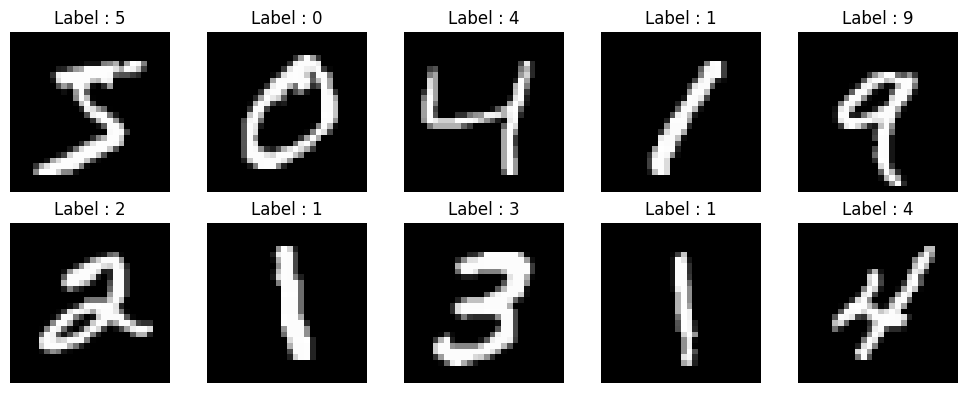

In [4]:
# Configuration de la figure pour afficher un échantillon de 10 images
plt.figure(figsize=(10, 4))
for i in range(10):
    # Sélection d'une sous-figure (2 lignes, 5 colonnes)
    plt.subplot(2, 5, i + 1)
    # .squeeze() retire le canal de couleur de dimension 1 pour pouvoir tracer l'image en 2D
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    # Affichage du label réel au-dessus de chaque image
    plt.title(f"Label : {y_train[i]}")
    # Masquage des axes pour un rendu visuel plus propre
    plt.axis("off")

# Ajustement automatique de l'espacement et affichage
plt.tight_layout()
plt.show()

## Questions de réflexion

1. Pourquoi divisons-nous la valeur des pixels par 255 ?
2. Quelle est l'utilité d'ajouter une dimension à la fin de chaque matrice d'image ?
3. Pourquoi conservons-nous les étiquettes sous forme d'entiers plutôt que de les stocker sous forme de texte ?

# Étape 2 - Construire et entraîner le CNN

Nous construisons un réseau composé de deux couches de convolution, de deux opérations de MaxPooling, puis de couches denses. Ce réseau produit un score pour chacun des dix chiffres.

In [5]:
# Construction de l'architecture du CNN séquentiel
model = tf.keras.Sequential([
    # Couche d'entrée qui définit la forme attendue de l'image (28, 28, 1)
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # Première convolution pour extraire 32 caractéristiques locales (filtres 3x3, activation ReLU)
    tf.keras.layers.Conv2D(32, kernel_size=3, activation="relu"),
    # Réduction de la dimension spatiale par 2 (MaxPooling)
    tf.keras.layers.MaxPooling2D(pool_size=2),
    # Deuxième convolution pour extraire 64 caractéristiques plus complexes
    tf.keras.layers.Conv2D(64, kernel_size=3, activation="relu"),
    # Deuxième réduction spatiale par 2
    tf.keras.layers.MaxPooling2D(pool_size=2),
    # Aplatissement du tenseur 3D en vecteur 1D avant les couches denses
    tf.keras.layers.Flatten(),
    # Couche entièrement connectée (Dense) de 128 neurones
    tf.keras.layers.Dense(128, activation="relu"),
    # Régularisation par Dropout de 20% pour limiter le surapprentissage (overfitting)
    tf.keras.layers.Dropout(0.2),
    # Couche de sortie générant les scores bruts (logits) pour les 10 classes de chiffres (0-9)
    tf.keras.layers.Dense(10)
])

# Affichage du récapitulatif des couches du modèle et du nombre de paramètres
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

La dernière couche renvoie des scores bruts appelés logits. La fonction SparseCategoricalCrossentropy prend ces logits en entrée pour calculer la perte.

La couche de Dropout désactive aléatoirement des neurones pendant l'entraînement pour éviter le surapprentissage. Pour générer les exemples adversariaux, nous désactivons ce comportement en passant le paramètre training à False.

In [6]:
# Définition de la fonction de perte (Cross-Entropy pour étiquettes sous forme d'entiers, à partir des logits)
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

# Compilation du modèle en associant l'optimiseur Adam, la fonction de perte et la métrique d'évaluation (Précision)
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=loss_object,
    metrics=["accuracy"]
)

## 2.1 - Entraîner le modèle

Nous définissons la durée d'entraînement à 5 époques. Une époque correspond à un passage complet sur les données d'entraînement.

In [7]:
# Enregistrement du temps de départ
start_time = time.time()

# Lancement de l'entraînement du modèle
history = model.fit(
    x_train,
    y_train,
    epochs=5,               # Le modèle verra l'ensemble des données 5 fois
    batch_size=128,          # Traitement des données par blocs de 128 images
    validation_split=0.1,    # Utilisation de 10% des données d'entraînement pour la validation
    verbose=1                # Affichage de la barre de progression et des métriques par epoch
)

# Calcul et affichage de la durée totale de l'entraînement
print("Durée d'entraînement :", round(time.time() - start_time, 1), "secondes")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.9254 - loss: 0.2479 - val_accuracy: 0.9837 - val_loss: 0.0580
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9786 - loss: 0.0693 - val_accuracy: 0.9890 - val_loss: 0.0423
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9840 - loss: 0.0503 - val_accuracy: 0.9883 - val_loss: 0.0404
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9878 - loss: 0.0398 - val_accuracy: 0.9897 - val_loss: 0.0398
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9907 - loss: 0.0307 - val_accuracy: 0.9878 - val_loss: 0.0417
Durée d'entraînement : 27.3 secondes


## 2.2 - Évaluer le CNN sur les images propres

In [8]:
# Évaluation des performances du modèle sur les images de test d'origine (propres)
clean_loss, clean_accuracy = model.evaluate(x_test, y_test, verbose=0)

# Affichage du score de précision de base
print(f"Précision sur le jeu de test propre : {clean_accuracy * 100:.2f} %")

Précision sur le jeu de test propre : 99.00 %


Cette précision sert de référence. Nous mesurerons l'effet de l'attaque en comparant les résultats sur ces mêmes images de test après perturbation.

Un modèle précis sur des données propres reste-t-il fiable face à des modifications calculées pour le tromper ?

# Étape 3 - Comprendre l'attaque FGSM

La méthode FGSM est une attaque en boîte blanche. L'attaquant accède à la structure du modèle et calcule le gradient de la perte par rapport à l'image d'entrée.

La formule de calcul est la suivante :

x_adv = clip(x + epsilon * sign(gradient_x(loss)), 0, 1)

Dans cette formule, x désigne l'image d'origine, loss représente la perte du modèle, et epsilon définit l'amplitude maximale de la modification. La fonction clip maintient les valeurs des pixels entre 0.0 et 1.0.

L'attaque cherche à augmenter la perte du modèle pour provoquer une mauvaise classification. Elle ne cherche pas à imposer une classe cible particulière.

Pour cette démonstration, l'attaque utilise les vraies étiquettes pour calculer la direction du gradient.

## 3.1 - Fonctionnement de tf.GradientTape

L'outil tf.GradientTape enregistre les opérations de calcul. TensorFlow utilise cet enregistrement pour évaluer le gradient de la perte par rapport aux pixels de l'image.

Cette étape ne modifie pas les paramètres du modèle. Elle ajuste uniquement les valeurs de l'image d'entrée.

In [9]:
def fgsm_attack(images, labels, epsilon):
    """Génère un batch d'images adversariales FGSM non ciblées."""
    # Conversion des entrées en tenseurs TensorFlow exploitables pour les gradients
    images = tf.convert_to_tensor(images, dtype=tf.float32)
    labels = tf.convert_to_tensor(labels, dtype=tf.int32)

    # Utilisation de GradientTape pour enregistrer les opérations sur l'image d'entrée
    with tf.GradientTape() as tape:
        tape.watch(images)                      # Indique à TensorFlow de suivre l'image pour les gradients
        logits = model(images, training=False)   # Prédiction (logits) en désactivant le Dropout
        loss = loss_object(labels, logits)       # Calcul de la perte associée à la vraie classe

    # Calcul du gradient de la perte par rapport aux pixels de l'image
    gradient = tape.gradient(loss, images)

    # Extraction du signe du gradient (-1, 0, ou 1) pour maximiser efficacement la perte
    signed_gradient = tf.sign(gradient)

    # Application de la perturbation dans la direction du signe du gradient pondéré par epsilon
    adversarial_images = images + epsilon * signed_gradient

    # Restriction des valeurs des pixels pour rester dans la plage valide [0.0, 1.0]
    adversarial_images = tf.clip_by_value(adversarial_images, 0.0, 1.0)

    return adversarial_images

## 3.2 - Tester FGSM sur une seule image

In [10]:
index = 0             # Index de l'image de test choisie pour la démonstration
epsilon_demo = 0.15   # Amplitude de perturbation choisie

# Extraction et conversion de l'image originale et de son étiquette réelle
original_image = tf.convert_to_tensor(x_test[index:index+1])
true_label = tf.convert_to_tensor(y_test[index:index+1])

# Génération de l'image perturbée via l'attaque FGSM
adversarial_image = fgsm_attack(original_image, true_label, epsilon_demo)

# Calcul des prédictions (logits) sur l'image propre et sur l'image adversariale
original_logits = model(original_image, training=False)
adversarial_logits = model(adversarial_image, training=False)

# Détermination des classes prédites (indice de la valeur maximale)
original_prediction = int(tf.argmax(original_logits[0]).numpy())
adversarial_prediction = int(tf.argmax(adversarial_logits[0]).numpy())

# Affichage comparatif des résultats avant et après l'attaque sur cette image
print("Vraie classe :", int(y_test[index]))
print("Prédiction originale :", original_prediction)
print("Prédiction adversariale :", adversarial_prediction)
print("Epsilon :", epsilon_demo)
print("Pixel min/max après perturbation :",
      float(tf.reduce_min(adversarial_image)),
      float(tf.reduce_max(adversarial_image)))

Vraie classe : 7
Prédiction originale : 7
Prédiction adversariale : 7
Epsilon : 0.15
Pixel min/max après perturbation : 0.0 1.0


L'attaque peut modifier la prédiction du modèle. L'efficacité varie selon l'image et la valeur d'epsilon choisie. Nous allons évaluer cette efficacité sur l'ensemble de test.

# Étape 4 - Mesurer l'effet de plusieurs valeurs d'epsilon

Nous testons les valeurs d'epsilon suivantes : 0.01, 0.05, 0.1, 0.2 et 0.3. La valeur 0 sert de point de comparaison.

In [11]:
def make_adversarial_dataset(model_to_attack, images, labels, epsilon, batch_size=256):
    """Génère un jeu adversarial par lots pour limiter l'utilisation mémoire."""
    adversarial_batches = []

    # Parcours séquentiel du dataset par lots de taille batch_size
    for start in range(0, len(images), batch_size):
        end = start + batch_size
        batch_x = tf.convert_to_tensor(images[start:end], dtype=tf.float32)
        batch_y = tf.convert_to_tensor(labels[start:end], dtype=tf.int32)

        # Enregistrement des gradients sur le lot d'images actuel
        with tf.GradientTape() as tape:
            tape.watch(batch_x)
            logits = model_to_attack(batch_x, training=False)
            loss = loss_object(batch_y, logits)
        gradients = tape.gradient(loss, batch_x)

        # Application de l'attaque FGSM et clipping sur le lot
        adv_batch = tf.clip_by_value(
            batch_x + epsilon * tf.sign(gradients), 0.0, 1.0
        )
        adversarial_batches.append(adv_batch.numpy())

    # Reconstitution du dataset complet en concaténant tous les lots
    return np.concatenate(adversarial_batches, axis=0)


def predict_labels(model_to_use, images, batch_size=512):
    """Prédit les classes par lots."""
    predictions = []
    # Parcours par lots pour éviter de saturer la mémoire graphique (VRAM)
    for start in range(0, len(images), batch_size):
        batch = tf.convert_to_tensor(images[start:start + batch_size], dtype=tf.float32)
        logits = model_to_use(batch, training=False)
        # Récupération de l'indice de la classe ayant obtenu le score le plus élevé
        predictions.append(tf.argmax(logits, axis=1).numpy())
    return np.concatenate(predictions)

## 4.1 - Précision du modèle et taux de réussite de l'attaque

La précision indique la part d'images correctement classées par le modèle.

Le taux de réussite de l'attaque mesure la part d'images initialement bien classées qui deviennent mal classées après l'ajout de la perturbation.

In [12]:
# Liste des valeurs d'epsilon (intensité de l'attaque) à tester
epsilons = [0.0, 0.01, 0.05, 0.1, 0.2, 0.3]

# Prédiction de référence sur les images propres de test pour identifier les prédictions correctes initiales
clean_predictions = predict_labels(model, x_test)
clean_correct = (clean_predictions == y_test)

results = []
adversarial_sets = {}

# Boucle sur chaque valeur d'epsilon pour évaluer l'impact de l'attaque
for epsilon in epsilons:
    if epsilon == 0.0:
        x_eval = x_test # Référence sans perturbation
    else:
        # Génération du jeu de test modifié pour l'epsilon en cours
        x_eval = make_adversarial_dataset(model, x_test, y_test, epsilon)
        adversarial_sets[epsilon] = x_eval

    # Évaluation de la précision globale du modèle sur ce dataset perturbé
    predictions = predict_labels(model, x_eval)
    accuracy = np.mean(predictions == y_test)

    # Calcul du taux de réussite de l'attaque (ASR) uniquement sur les images initialement bien classées
    if np.any(clean_correct):
        attack_success = np.mean(predictions[clean_correct] != y_test[clean_correct])
    else:
        attack_success = np.nan

    # Enregistrement des statistiques pour cette intensité d'attaque
    results.append({
        "epsilon": epsilon,
        "accuracy": accuracy,
        "attack_success_rate": attack_success
    })

# Conversion des résultats en DataFrame Pandas pour un affichage tabulaire clair
results_df = pd.DataFrame(results)
display(results_df)

,epsilon,accuracy,attack_success_rate
0,0.00,0.9900,0.000000
1,0.01,0.9863,0.003737
2,0.05,0.9644,0.025859
3,0.10,0.8999,0.091010
4,0.20,0.5363,0.458283
5,0.30,0.1572,0.841212


## 4.2 - Tracer la précision en fonction d'epsilon

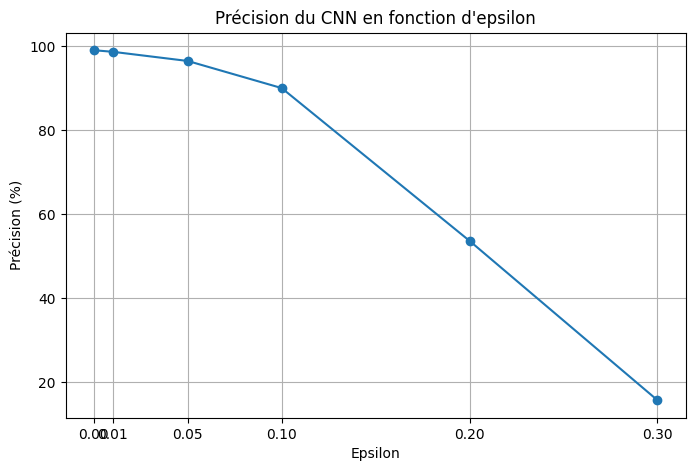

In [13]:
# Création d'un graphique linéaire montrant la chute de la précision du modèle
plt.figure(figsize=(8, 5))
plt.plot(results_df["epsilon"], results_df["accuracy"] * 100, marker="o")
plt.title("Précision du CNN en fonction d'epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Précision (%)")
plt.xticks(epsilons)
plt.grid(True)
plt.show()

## 4.3 - Tracer le taux de réussite de l'attaque

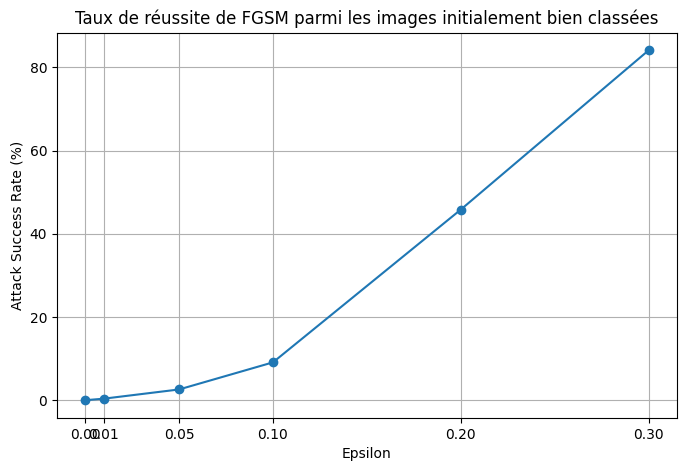

In [14]:
# Création d'un graphique linéaire montrant l'augmentation du taux de réussite de l'attaque
plt.figure(figsize=(8, 5))
plt.plot(
    results_df["epsilon"],
    results_df["attack_success_rate"] * 100,
    marker="o"
)
plt.title("Taux de réussite de FGSM parmi les images initialement bien classées")
plt.xlabel("Epsilon")
plt.ylabel("Attack Success Rate (%)")
plt.xticks(epsilons)
plt.grid(True)
plt.show()

## Questions d'analyse

1. Comment la précision évolue-t-elle lorsque le paramètre epsilon augmente ?
2. À partir de quel seuil d'epsilon observez-vous une diminution marquée de la précision ?
3. Pourquoi la précision obtenue avec un epsilon de 0 est-elle égale à la précision de référence ?
4. Pourquoi le taux de réussite de l'attaque n'est-il pas égal à la différence entre 1 et la précision ?
5. Quelle est la différence entre diminuer la précision globale et réussir une attaque sur une image correcte ?

# Étape 5 - Visualiser les images adversariales

Le script suivant affiche l'image d'origine, la perturbation multipliée par 10 pour être visible, et l'image modifiée finale.

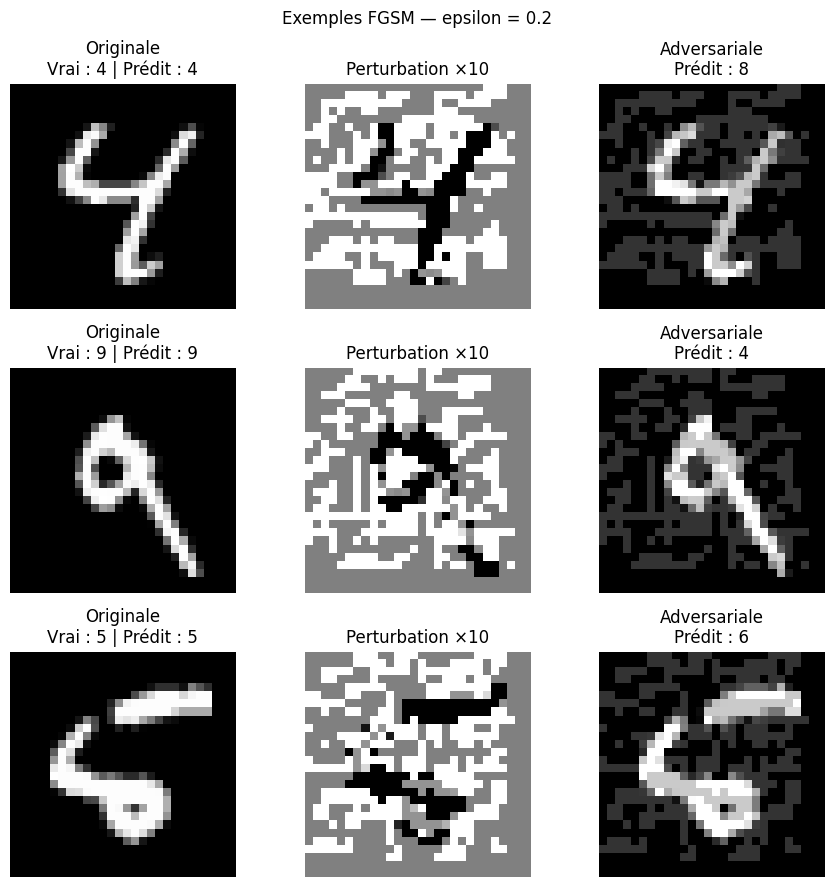

In [15]:
epsilon_visual = 0.2

# Récupération ou génération à la volée du dataset adversarial pour l'epsilon sélectionné
x_adv_visual = adversarial_sets.get(epsilon_visual)
if x_adv_visual is None:
    x_adv_visual = make_adversarial_dataset(model, x_test, y_test, epsilon_visual)
    adversarial_sets[epsilon_visual] = x_adv_visual

# Prédictions du modèle sur ces images perturbées
adv_predictions_visual = predict_labels(model, x_adv_visual)

# Sélection des exemples qui étaient corrects avant mais qui ont échoué après l'attaque
candidates = np.where(clean_correct & (adv_predictions_visual != y_test))[0]
if len(candidates) < 3:
    candidates = np.where(clean_correct)[0]

# Sélection des 3 premiers exemples candidats à afficher
selected_indices = candidates[:3]

# Initialisation de la grille d'affichage (3 colonnes : Originale, Perturbation, Adversariale)
fig, axes = plt.subplots(len(selected_indices), 3, figsize=(9, 3 * len(selected_indices)))
if len(selected_indices) == 1:
    axes = np.expand_dims(axes, axis=0)

# Boucle pour dessiner chaque ligne d'exemples
for row, idx in enumerate(selected_indices):
    original = x_test[idx].squeeze() # Image originale
    adversarial = x_adv_visual[idx].squeeze() # Image adversariale correspondante
    perturbation = adversarial - original # Différence exacte (la perturbation appliquée)

    # Amplification visuelle de la perturbation (multipliée par 10) centrée sur le gris moyen (0.5)
    perturbation_display = np.clip(0.5 + 10 * perturbation, 0, 1)

    # Affichage de l'image originale et ses informations
    axes[row, 0].imshow(original, cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Originale\nVrai : {y_test[idx]} | Prédit : {clean_predictions[idx]}")

    # Affichage de la perturbation isolée et amplifiée
    axes[row, 1].imshow(perturbation_display, cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Perturbation ×10")

    # Affichage de l'image modifiée finale vue par le modèle et sa prédiction incorrecte
    axes[row, 2].imshow(adversarial, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title(f"Adversariale\nPrédit : {adv_predictions_visual[idx]}")

    # Masquage des coordonnées sur chaque graphique pour la lisibilité
    for ax in axes[row]:
        ax.axis("off")

# Ajout du titre global et rendu
plt.suptitle(f"Exemples FGSM — epsilon = {epsilon_visual}")
plt.tight_layout()
plt.show()

## 5.1 - Contrôler les contraintes sur les pixels

La perturbation respecte la limite imposée par le paramètre epsilon. L'opération de clipping maintient chaque pixel dans l'intervalle de valeurs autorisé.

In [16]:
# Calcul de la déviation maximale pixel par pixel entre l'image modifiée et l'image d'origine
max_difference = np.max(np.abs(x_adv_visual - x_test))
print("Différence absolue maximale observée :", float(max_difference))
print("Epsilon demandé :", epsilon_visual)
print("Pixel min/max :", float(x_adv_visual.min()), float(x_adv_visual.max()))

# Assertions de sécurité pour garantir que le code respecte bien les limites physiques et l'epsilon mathématique
assert x_adv_visual.min() >= 0.0
assert x_adv_visual.max() <= 1.0
assert max_difference <= epsilon_visual + 1e-6
print("Vérifications réussies.")

Différence absolue maximale observée : 0.20000001788139343
Epsilon demandé : 0.2
Pixel min/max : 0.0 1.0
Vérifications réussies.


## Questions d'analyse

1. La perturbation appliquée est-elle visible sur l'image modifiée ?
2. Pourquoi est-il nécessaire de multiplier la perturbation par 10 pour l'observer ?
3. L'attaque FGSM réussit-elle à tromper le modèle sur toutes les images ?
4. Pourquoi la perception humaine de la perturbation ne correspond-elle pas toujours à la sensibilité du modèle ?

# Étape 6 - Entraînement adversarial

L'entraînement adversarial consiste à intégrer des exemples perturbés dans les données d'apprentissage. Nous créons un jeu de données contenant 50 % d'images propres et 50 % d'images modifiées par FGSM. Nous entraînons ensuite une copie du modèle sur ce mélange.

Les paramètres de cette étape sont :

* Epsilon d'entraînement de 0.1.
* Échantillon de départ de 20000 images.
* Proportion égale de données propres et modifiées.
* Entraînement limité à 3 époques.

Ce volume réduit permet d'exécuter le calcul rapidement sur Colab.

## 6.1 - Générer les images perturbées pour l'entraînement

In [17]:
train_subset_size = 20000
epsilon_training = 0.1

# Extraction d'un échantillon d'images et d'étiquettes d'entraînement de taille restreinte
x_train_subset = x_train[:train_subset_size]
y_train_subset = y_train[:train_subset_size]

# Enregistrement du temps de départ
start_time = time.time()

# Génération d'exemples adversariaux pour chaque image de ce sous-ensemble
x_train_adv = make_adversarial_dataset(
    model,
    x_train_subset,
    y_train_subset,
    epsilon_training,
    batch_size=256
)

# Affichage de confirmation et durée d'exécution
print("Exemples adversariaux générés :", x_train_adv.shape)
print("Durée :", round(time.time() - start_time, 1), "secondes")

Exemples adversariaux générés : (20000, 28, 28, 1)
Durée : 2.1 secondes


## 6.2 - Mélanger les images propres et les images perturbées

In [18]:
# Fusion des images d'entraînement d'origine (propres) avec les images attaquées (adversariales)
x_mixed = np.concatenate([x_train_subset, x_train_adv], axis=0)
y_mixed = np.concatenate([y_train_subset, y_train_subset], axis=0)

# Mélange aléatoire des données pour assurer une bonne distribution lors de l'apprentissage
rng = np.random.default_rng(SEED)
permutation = rng.permutation(len(x_mixed))
x_mixed = x_mixed[permutation]
y_mixed = y_mixed[permutation]

print("Taille du jeu mélangé :", x_mixed.shape) # Doit faire 40 000 images (20k propres + 20k adversariales)

Taille du jeu mélangé : (40000, 28, 28, 1)


## 6.3 - Entraîner la copie du modèle

Nous copions les poids du premier modèle pour appliquer un entraînement complémentaire.

In [19]:
# Clonage de la structure du réseau d'origine pour en faire une instance de modèle robuste distincte
robust_model = tf.keras.models.clone_model(model)
# Copie des poids du premier modèle pour partir de la même base de connaissances
robust_model.set_weights(model.get_weights())

# Compilation du modèle robuste avec un taux d'apprentissage plus faible (fine-tuning)
robust_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=loss_object,
    metrics=["accuracy"]
)

# Poursuite de l'entraînement (fine-tuning) du modèle robuste sur le dataset mixte (propre + adversarial)
robust_history = robust_model.fit(
    x_mixed,
    y_mixed,
    epochs=3,                 # 3 epochs d'adaptation
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9521 - loss: 0.1377 - val_accuracy: 0.9678 - val_loss: 0.0958
Epoch 2/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9648 - loss: 0.1024 - val_accuracy: 0.9730 - val_loss: 0.0796
Epoch 3/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9703 - loss: 0.0863 - val_accuracy: 0.9755 - val_loss: 0.0715


## 6.4 - Comparer les performances des modèles

Chaque modèle est évalué face à des images adversariales générées à partir de ses propres gradients. Cette méthode assure une comparaison équitable en boîte blanche.

In [20]:
comparison_rows = []

# Boucle de comparaison entre le modèle de base et le modèle robuste face à différentes intensités de perturbation
for model_name, model_to_test in [
    ("CNN initial", model),
    ("CNN adversarial training", robust_model)
]:
    # Évaluation de base (sans perturbation)
    clean_pred = predict_labels(model_to_test, x_test)
    clean_acc = np.mean(clean_pred == y_test)

    # Évaluation de la robustesse sous différents niveaux d'attaque en boîte blanche active (basée sur son propre gradient)
    for epsilon in [0.0, 0.05, 0.1, 0.2, 0.3]:
        if epsilon == 0.0:
            x_eval = x_test
        else:
            # Attaque en boîte blanche ciblée sur le modèle en cours d'évaluation
            x_eval = make_adversarial_dataset(
                model_to_test, x_test, y_test, epsilon, batch_size=256
            )
        adv_pred = predict_labels(model_to_test, x_eval)
        adv_acc = np.mean(adv_pred == y_test)

        # Stockage de la mesure de précision
        comparison_rows.append({
            "Modèle": model_name,
            "Epsilon": epsilon,
            "Précision (%)": round(adv_acc * 100, 2)
        })

# Conversion et affichage des résultats sous forme de tableau comparatif
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Modèle,Epsilon,Précision (%)
0,CNN initial,0.00,99.00
1,CNN initial,0.05,96.44
2,CNN initial,0.10,89.99
3,CNN initial,0.20,53.63
4,CNN initial,0.30,15.72
5,CNN adversarial training,0.00,99.06
6,CNN adversarial training,0.05,97.48
7,CNN adversarial training,0.10,93.57
8,CNN adversarial training,0.20,70.26
9,CNN adversarial training,0.30,27.16


## 6.5 - Graphique comparatif

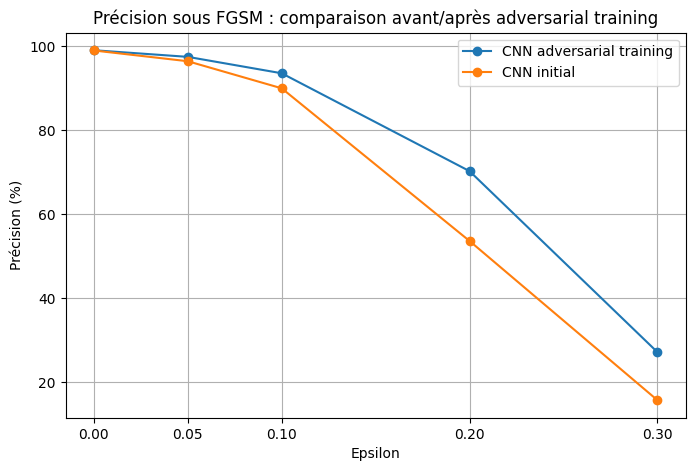

In [21]:
# Tracé des courbes comparatives de robustesse avant et après l'entraînement adversarial
plt.figure(figsize=(8, 5))
for model_name, group in comparison_df.groupby("Modèle"):
    plt.plot(group["Epsilon"], group["Précision (%)"], marker="o", label=model_name)

plt.title("Précision sous FGSM : comparaison avant/après adversarial training")
plt.xlabel("Epsilon")
plt.ylabel("Précision (%)")
plt.xticks([0.0, 0.05, 0.1, 0.2, 0.3])
plt.grid(True)
plt.legend()
plt.show()

## Questions d'analyse

1. Comment la précision sur les images propres évolue-t-elle après cet entraînement ?
2. Le modèle entraîné avec des exemples perturbés résiste-t-il mieux à une attaque d'intensité 0.1 ?
3. Cette amélioration de la robustesse persiste-t-elle pour des valeurs d'epsilon plus élevées ?
4. Observez-vous une tension entre la précision sur les données propres et la précision sur les données modifiées ?
5. Pourquoi est-il nécessaire de tester d'autres types d'attaques avant de déclarer qu'un modèle est sécurisé ?

# Étape 7 - Synthèse et livrables

## Documents à fournir

1. Le notebook Colab exécuté affichant toutes les sorties de code.
2. Le graphique représentant la précision selon la valeur d'epsilon.
3. Les images affichant l'exemple original, la perturbation et le résultat final de l'attaque.
4. Une analyse rédigée de 5 à 10 lignes expliquant ce que cette expérience montre sur la robustesse des modèles CNN.

L'évaluation prend en compte la configuration des données, l'exactitude de l'implémentation de l'attaque, la qualité des graphiques et la précision de votre analyse rédigée.

## Conclusion

La méthode FGSM montre qu'un attaquant peut tromper un modèle avec de faibles modifications calculées à partir des gradients. La fiabilité d'un modèle doit s'évaluer à la fois sur des données classiques et face à des perturbations ciblées.

Le jeu MNIST est simple et l'attaque FGSM s'exécute en une seule étape. Ces résultats expérimentaux ne suffisent pas à garantir la sécurité d'un modèle dans un environnement de production réel.